# Electricity Consumption Analysis & Power Demand Dashboard
This notebook analyzes a synthetic hourly electricity-consumption dataset using Pandas, NumPy, and Matplotlib.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 1. Load data

In [9]:
df = pd.read_csv("../data/raw/electricity_data.csv")
df.head()



,Date,Time,Consumption_kWh
0,2025-01-01,00:00,202.18
1,2025-01-01,01:00,188.94
2,2025-01-01,02:00,207.39
3,2025-01-01,03:00,210.71
4,2025-01-01,04:00,185.15


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8768 entries, 0 to 8767
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             8768 non-null   object 
 1   Time             8768 non-null   object 
 2   Consumption_kWh  8756 non-null   float64
dtypes: float64(1), object(2)
memory usage: 205.6+ KB


## 2. Inspect data quality

In [6]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df.describe(include='all')


Shape: (8768, 3)

Data types:
Date                object
Time                object
Consumption_kWh    float64
dtype: object

Missing values:
Date                0
Time                0
Consumption_kWh    12
dtype: int64

Duplicate rows: 8


,Date,Time,Consumption_kWh
count,8768,8768,8756.000000
unique,365,24,NaN
top,2025-08-06,22:00,NaN
freq,25,366,NaN
mean,NaN,NaN,227.936010
std,NaN,NaN,45.862445
min,NaN,NaN,105.220000
25%,NaN,NaN,194.827500
50%,NaN,NaN,228.455000
75%,NaN,NaN,258.902500


In [8]:
df.duplicated().sum()

0

## 3. Clean and transform

In [16]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.drop_duplicates().copy()
df = df.sort_values(["Date", "Time"]).reset_index(drop=True)
df["Consumption_kWh"] = df["Consumption_kWh"].interpolate(method="linear").ffill().bfill()
df["DateTime"] = pd.to_datetime(df["Date"].dt.strftime("%Y-%m-%d") + " " + df["Time"])
df["Hour"] = df["DateTime"].dt.hour
df["Day"] = df["DateTime"].dt.day
df["Month"] = df["DateTime"].dt.month
df["Month_Name"] = df["DateTime"].dt.month_name()
df["Day_of_Week"] = df["DateTime"].dt.day_name()
threshold = df["Consumption_kWh"].quantile(0.90)
df["Peak_Flag"] = np.where(df["Consumption_kWh"] >= threshold, "Peak", "Normal")
df.head()


,Date,Time,Consumption_kWh,DateTime,Hour,Day,Month,Month_Name,Day_of_Week,Peak_Flag
0,2025-01-01,00:00,202.18,2025-01-01 00:00:00,0,1,1,January,Wednesday,Normal
1,2025-01-01,01:00,188.94,2025-01-01 01:00:00,1,1,1,January,Wednesday,Normal
2,2025-01-01,02:00,207.39,2025-01-01 02:00:00,2,1,1,January,Wednesday,Normal
3,2025-01-01,03:00,210.71,2025-01-01 03:00:00,3,1,1,January,Wednesday,Normal
4,2025-01-01,04:00,185.15,2025-01-01 04:00:00,4,1,1,January,Wednesday,Normal


## 4. KPI analysis

In [17]:
print("Total consumption:", df["Consumption_kWh"].sum())
print("Average hourly consumption:", df["Consumption_kWh"].mean())
print("Peak demand:", df["Consumption_kWh"].max())
print("Minimum demand:", df["Consumption_kWh"].min())
print("\nPeak period:")
print(df.loc[df["Consumption_kWh"].idxmax()])


Total consumption: 1997001.455
Average hourly consumption: 227.9682026255708
Peak demand: 365.12
Minimum demand: 105.22

Peak period:
Date               2025-01-06 00:00:00
Time                             19:00
Consumption_kWh                 365.12
DateTime           2025-01-06 19:00:00
Hour                                19
Day                                  6
Month                                1
Month_Name                     January
Day_of_Week                     Monday
Peak_Flag                         Peak
Name: 139, dtype: object


In [18]:
df.columns

Index(['Date', 'Time', 'Consumption_kWh', 'DateTime', 'Hour', 'Day', 'Month',
       'Month_Name', 'Day_of_Week', 'Peak_Flag'],
      dtype='object')

## 5. Hourly consumption

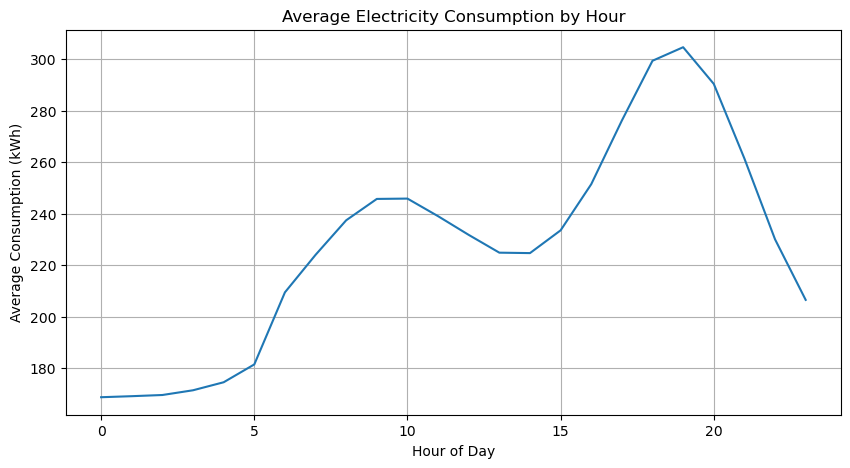

In [19]:
hourly_consumption = df.groupby("Hour")["Consumption_kWh"].mean()
plt.figure(figsize=(10,5))
plt.plot(hourly_consumption.index, hourly_consumption.values)
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (kWh)")
plt.title("Average Electricity Consumption by Hour")
plt.grid(True)
plt.show()


## 6. Daily consumption

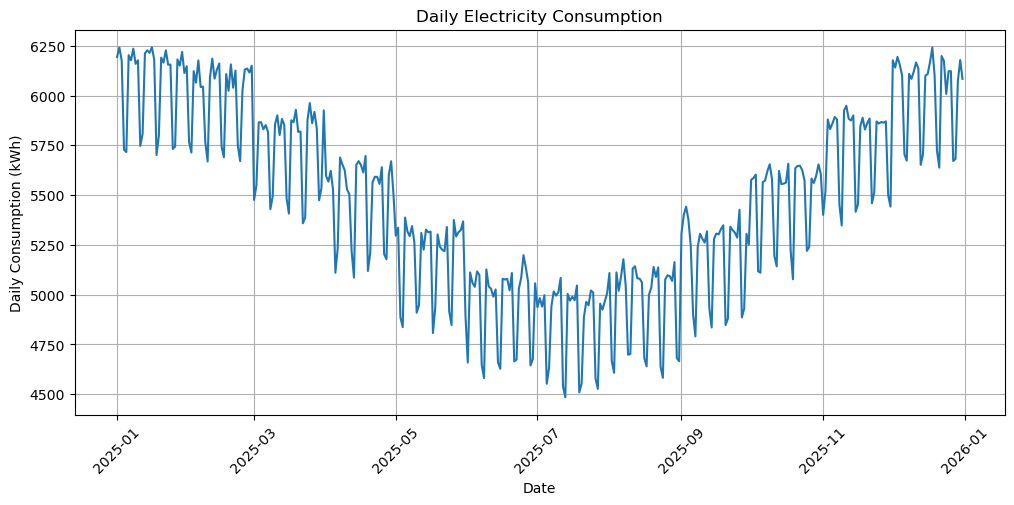

In [20]:
daily_consumption = df.groupby("Date")["Consumption_kWh"].sum()
plt.figure(figsize=(12,5))
plt.plot(daily_consumption.index, daily_consumption.values)
plt.xlabel("Date")
plt.ylabel("Daily Consumption (kWh)")
plt.title("Daily Electricity Consumption")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


## 7. Monthly consumption

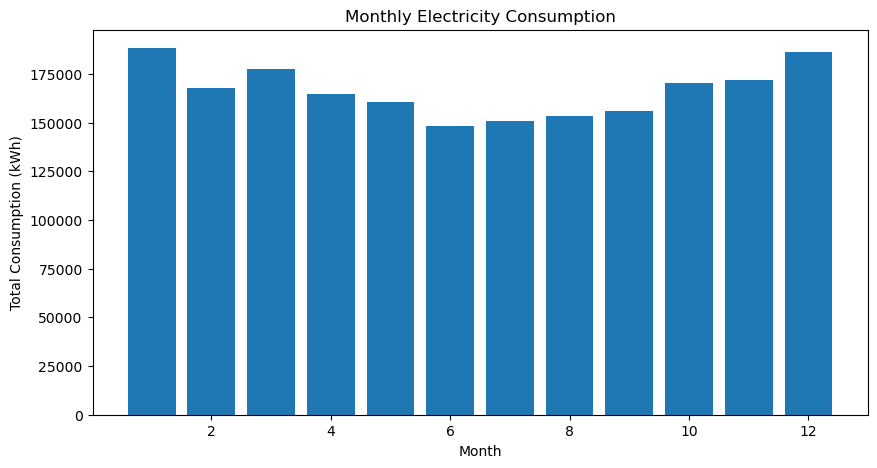

In [21]:
monthly_consumption = df.groupby("Month")["Consumption_kWh"].sum()
plt.figure(figsize=(10,5))
plt.bar(monthly_consumption.index, monthly_consumption.values)
plt.xlabel("Month")
plt.ylabel("Total Consumption (kWh)")
plt.title("Monthly Electricity Consumption")
plt.show()


## 8. Day-of-week analysis

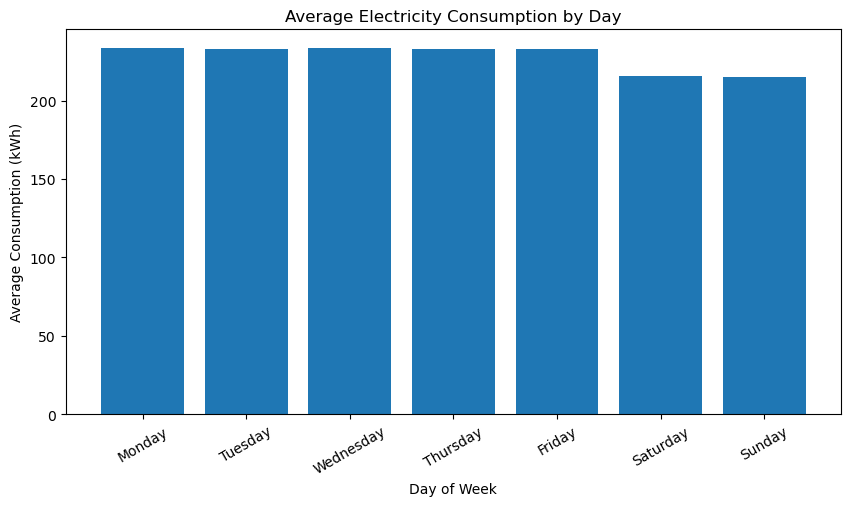

In [22]:
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_consumption = df.groupby("Day_of_Week")["Consumption_kWh"].mean().reindex(weekday_order)
plt.figure(figsize=(10,5))
plt.bar(weekday_consumption.index, weekday_consumption.values)
plt.xlabel("Day of Week")
plt.ylabel("Average Consumption (kWh)")
plt.title("Average Electricity Consumption by Day")
plt.xticks(rotation=30)
plt.show()


## 9. Peak vs normal observations

In [23]:
print(df["Peak_Flag"].value_counts())
print("\nPeak threshold:", threshold)


Normal    7884
Peak       876
Name: Peak_Flag, dtype: int64

Peak threshold: 288.656


## 10. Export cleaned data

In [27]:
df.to_csv("../data/cleaned/electricity_cleaned.csv", index=False)
print("Saved cleaned dataset.")


Saved cleaned dataset.


In [28]:
cleaned_df = pd.read_csv("../data/cleaned/electricity_cleaned.csv")

cleaned_df.head()

,Date,Time,Consumption_kWh,DateTime,Hour,Day,Month,Month_Name,Day_of_Week,Peak_Flag
0,2025-01-01,00:00,202.18,2025-01-01 00:00:00,0,1,1,January,Wednesday,Normal
1,2025-01-01,01:00,188.94,2025-01-01 01:00:00,1,1,1,January,Wednesday,Normal
2,2025-01-01,02:00,207.39,2025-01-01 02:00:00,2,1,1,January,Wednesday,Normal
3,2025-01-01,03:00,210.71,2025-01-01 03:00:00,3,1,1,January,Wednesday,Normal
4,2025-01-01,04:00,185.15,2025-01-01 04:00:00,4,1,1,January,Wednesday,Normal


In [25]:
df.shape

(8760, 10)

In [26]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df.describe(include='all')

Shape: (8760, 10)

Data types:
Date               datetime64[ns]
Time                       object
Consumption_kWh           float64
DateTime           datetime64[ns]
Hour                        int64
Day                         int64
Month                       int64
Month_Name                 object
Day_of_Week                object
Peak_Flag                  object
dtype: object

Missing values:
Date               0
Time               0
Consumption_kWh    0
DateTime           0
Hour               0
Day                0
Month              0
Month_Name         0
Day_of_Week        0
Peak_Flag          0
dtype: int64

Duplicate rows: 0


C:\Users\HP\AppData\Local\Temp\ipykernel_7404\538300322.py:7: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  df.describe(include='all')
C:\Users\HP\AppData\Local\Temp\ipykernel_7404\538300322.py:7: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  df.describe(include='all')


,Date,Time,Consumption_kWh,DateTime,Hour,Day,Month,Month_Name,Day_of_Week,Peak_Flag
count,8760,8760,8760.000000,8760,8760.000000,8760.000000,8760.000000,8760,8760,8760
unique,365,24,NaN,8760,NaN,NaN,NaN,12,7,2
top,2025-01-01 00:00:00,00:00,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,January,Wednesday,Normal
freq,24,365,NaN,1,NaN,NaN,NaN,744,1272,7884
first,2025-01-01 00:00:00,NaN,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
last,2025-12-31 00:00:00,NaN,NaN,2025-12-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,227.968203,NaN,11.500000,15.720548,6.526027,NaN,NaN,NaN
std,NaN,NaN,45.875990,NaN,6.922582,8.796749,3.448048,NaN,NaN,NaN
min,NaN,NaN,105.220000,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN
25%,NaN,NaN,194.827500,NaN,5.750000,8.000000,4.000000,NaN,NaN,NaN
